# Decision Tree - Rukmalgoda R.D.D. (IT25101160)


## 1. Model Suitability

**Why Decision Tree for Wisconsin Breast Cancer data?**

- Features are ordinal / continuous with natural thresholds (e.g., Clump Thickness > 5) then trees split easily.
- Highly interpretable – doctors can follow the decision path.
- Handles non-linear relationships and feature interactions automatically.
- No need for feature scaling (trees are scale-invariant) – useful comparison against scaled vs unscaled.
- Fast training and prediction; easy to visualise.


In [ ]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# GOOGLE DRIVE MOUNT & LOAD PREPROCESSED DATA
# Student: Rukmalgoda R.D.D. (IT25101160)
# Algorithm: Decision Tree
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/results/outputs/processed_breast_cancer.csv'
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df['Class'].value_counts())
df.head()

Mounted at /content/drive
Dataset shape: (699, 20)
Class
0    458
1    241
Name: count, dtype: int64


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


In [ ]:
# ============================================================
# DATA PREPARATION
# ============================================================
df = df.drop(columns=['Sample_code_number'], errors='ignore')

feature_cols_orig = [
    'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
    'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
    'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses'
]
feature_cols_scaled = [c + '_scaled' for c in feature_cols_orig]

X_orig = df[feature_cols_orig].values
X_scaled = df[feature_cols_scaled].values
y = df['Class'].values

print("Original features shape:", X_orig.shape)
print("Scaled features shape  :", X_scaled.shape)
print("Target shape           :", y.shape)
print("Class balance          :", np.bincount(y))

Original features shape: (699, 9)
Scaled features shape  : (699, 9)
Target shape           : (699,)
Class balance          : [458 241]


In [ ]:
# ============================================================
# TRAIN / TEST SPLIT (Stratified 80/20)
# ============================================================
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)
X_train_scaled, X_test_scaled, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
print("Train size:", X_train_orig.shape[0])
print("Test size :", X_test_orig.shape[0])
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution :", np.bincount(y_test))

Train size: 559
Test size : 140
Train class distribution: [366 193]
Test class distribution : [92 48]


In [ ]:
# ============================================================
# EVALUATION HELPER FUNCTION
# ============================================================
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if len(np.unique(y_prob)) > 1 else 0.0
    }
    print(f"\n========== {model_name} ==========")
    print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print(f"ROC-AUC: {metrics['ROC-AUC']:.4f}")
    return metrics, y_pred, y_prob

## 2. Implementation – Decision Tree Varieties

| Variety | Description |
|---------|-------------|
| V1 Baseline | Default DecisionTreeClassifier (unlimited depth) |
| V2 Pruned | max_depth=4, min_samples_leaf=5 (manual) |
| V3 GridSearchCV | Full search over criterion, depth, min_samples |
| V4 Scaled features | Best params on scaled data (should be similar) |


In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# ------------------------------------------------------------
# Variety 1 – Baseline (unpruned)
# ------------------------------------------------------------
dt_v1 = DecisionTreeClassifier(random_state=42)
metrics_v1, y_pred_v1, y_prob_v1 = evaluate_model(
    dt_v1, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V1: Decision Tree (Baseline, Unpruned)"
)
print("Tree depth:", dt_v1.get_depth())
print("Number of leaves:", dt_v1.get_n_leaves())


========== V1: Decision Tree (Baseline, Unpruned) ==========
               precision    recall  f1-score   support

   Benign (0)       0.93      0.97      0.95        92
Malignant (1)       0.93      0.85      0.89        48

     accuracy                           0.93       140
    macro avg       0.93      0.91      0.92       140
 weighted avg       0.93      0.93      0.93       140

Confusion Matrix:
[[89  3]
 [ 7 41]]
ROC-AUC: 0.9108
Tree depth: 9
Number of leaves: 29


In [ ]:
# ------------------------------------------------------------
# Variety 2 – Manually Pruned
# ------------------------------------------------------------
dt_v2 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    min_samples_split=10,
    criterion='gini',
    random_state=42
)
metrics_v2, y_pred_v2, y_prob_v2 = evaluate_model(
    dt_v2, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V2: Decision Tree (Pruned depth=4)"
)


========== V2: Decision Tree (Pruned depth=4) ==========
               precision    recall  f1-score   support

   Benign (0)       0.95      0.93      0.94        92
Malignant (1)       0.88      0.90      0.89        48

     accuracy                           0.92       140
    macro avg       0.91      0.92      0.91       140
 weighted avg       0.92      0.92      0.92       140

Confusion Matrix:
[[86  6]
 [ 5 43]]
ROC-AUC: 0.9664


In [ ]:
# ------------------------------------------------------------
# Variety 3 – GridSearchCV
# ------------------------------------------------------------
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 3, 5],
    'max_features': [None, 'sqrt']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_dt.fit(X_train_orig, y_train)

print("Best parameters :", grid_dt.best_params_)
print("Best CV F1 score:", grid_dt.best_score_)

dt_v3 = grid_dt.best_estimator_
metrics_v3, y_pred_v3, y_prob_v3 = evaluate_model(
    dt_v3, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V3: Decision Tree (GridSearchCV Best)"
)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters : {'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV F1 score: 0.9416239600949794

========== V3: Decision Tree (GridSearchCV Best) ==========
               precision    recall  f1-score   support

   Benign (0)       0.96      0.96      0.96        92
Malignant (1)       0.92      0.92      0.92        48

     accuracy                           0.94       140
    macro avg       0.94      0.94      0.94       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
[[88  4]
 [ 4 44]]
ROC-AUC: 0.9476


In [ ]:
# ------------------------------------------------------------
# Variety 4 – Best params on SCALED features
# ------------------------------------------------------------
dt_v4 = DecisionTreeClassifier(**grid_dt.best_params_, random_state=42)
metrics_v4, y_pred_v4, y_prob_v4 = evaluate_model(
    dt_v4, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V4: Decision Tree (Best params, Scaled)"
)


========== V4: Decision Tree (Best params, Scaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.96      0.96      0.96        92
Malignant (1)       0.92      0.92      0.92        48

     accuracy                           0.94       140
    macro avg       0.94      0.94      0.94       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
[[88  4]
 [ 4 44]]
ROC-AUC: 0.9476


## 3. Comparison & Visualisation


In [ ]:
results_df = pd.DataFrame([metrics_v1, metrics_v2, metrics_v3, metrics_v4])
results_df = results_df.set_index('Model')
print(results_df.round(4).to_string())
print("\n>>> Best F1-Score :", results_df['F1-Score'].idxmax(), f"({results_df['F1-Score'].max():.4f})")

                                         Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                                  
V1: Decision Tree (Baseline, Unpruned)     0.9286     0.9318  0.8542    0.8913   0.9108
V2: Decision Tree (Pruned depth=4)         0.9214     0.8776  0.8958    0.8866   0.9664
V3: Decision Tree (GridSearchCV Best)      0.9429     0.9167  0.9167    0.9167   0.9476
V4: Decision Tree (Best params, Scaled)    0.9429     0.9167  0.9167    0.9167   0.9476

>>> Best F1-Score : V3: Decision Tree (GridSearchCV Best) (0.9167)


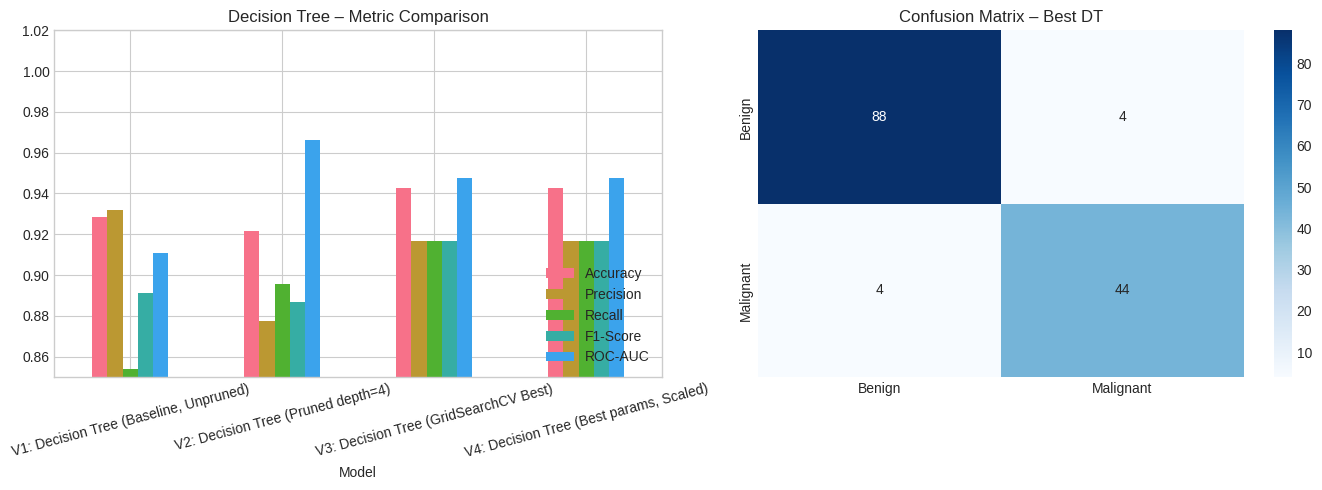

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].plot(kind='bar', ax=axes[0], rot=15)
axes[0].set_title('Decision Tree – Metric Comparison')
axes[0].set_ylim(0.85, 1.02)
axes[0].legend(loc='lower right')

cm = confusion_matrix(y_test, y_pred_v3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
axes[1].set_title('Confusion Matrix – Best DT')
plt.tight_layout()
plt.show()

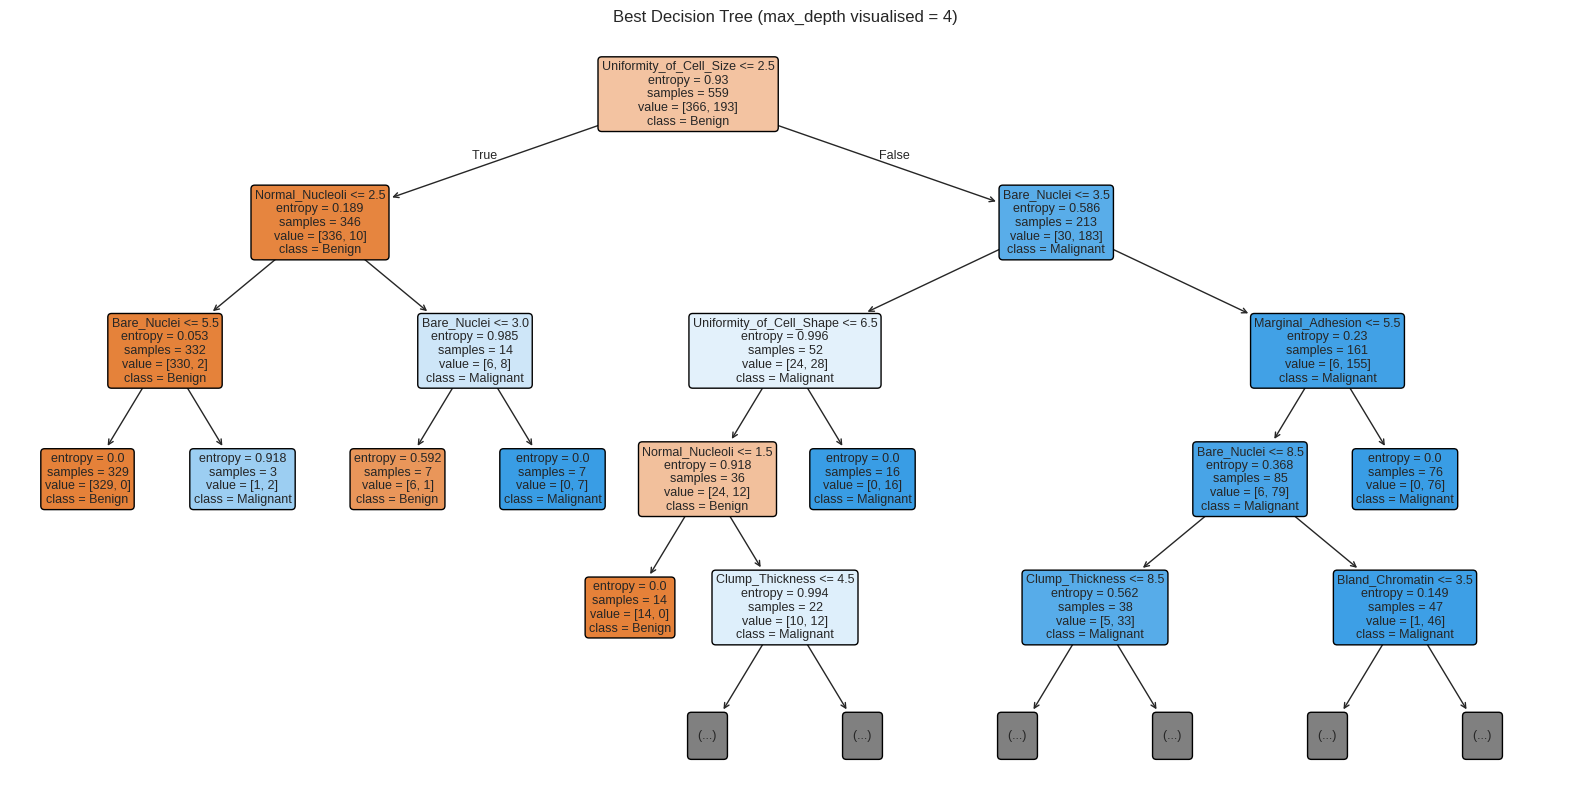

                    Feature  Importance
    Uniformity_of_Cell_Size    0.696653
                Bare_Nuclei    0.134585
            Normal_Nucleoli    0.095388
   Uniformity_of_Cell_Shape    0.039580
            Clump_Thickness    0.016941
          Marginal_Adhesion    0.012007
            Bland_Chromatin    0.004846
Single_Epithelial_Cell_Size    0.000000
                    Mitoses    0.000000


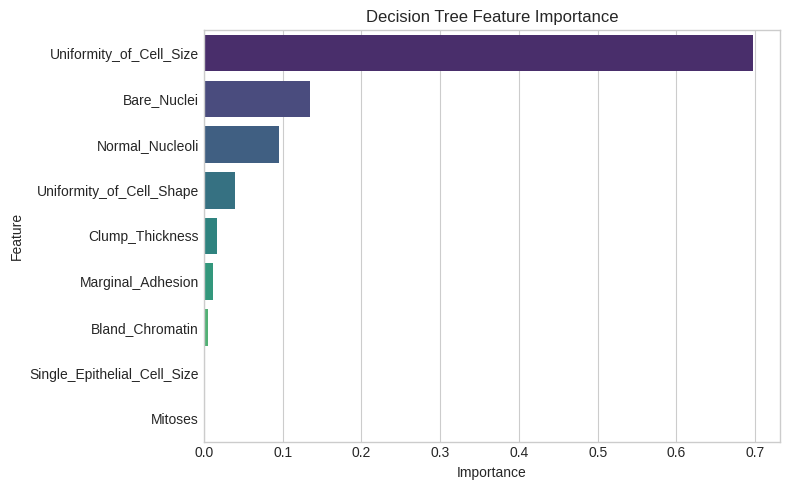

In [ ]:
# Visualise the best tree (limited depth for readability)
plt.figure(figsize=(20, 10))
plot_tree(dt_v3, feature_names=feature_cols_orig, class_names=['Benign', 'Malignant'],
          filled=True, rounded=True, fontsize=9, max_depth=4)
plt.title('Best Decision Tree (max_depth visualised = 4)')
plt.show()

# Feature importance
imp_df = pd.DataFrame({
    'Feature': feature_cols_orig,
    'Importance': dt_v3.feature_importances_
}).sort_values('Importance', ascending=False)
print(imp_df.to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Decision Tree Feature Importance')
plt.tight_layout()
plt.show()

## 4. Validation Method
- Stratified 80/20 split + Stratified 5-Fold CV inside GridSearchCV.
- Scoring: F1-Score.
- Trees are scale-invarian. Original features preferred for interpretability.

## 5. Conclusion
- Unpruned trees overfit; pruning / GridSearch improves generalisation.
- Decision Tree gives excellent interpretability and competitive accuracy.
- **Recommended**: Variety 3 (GridSearchCV best).

## 6. Limitations & Improvements
| Limitation | Improvement |
|------------|-------------|
| High variance (unstable) | Use Random Forest / ensemble |
| Can overfit deep trees | Pruning, max_depth, min_samples_leaf |
| Axis-aligned splits only | Oblique trees or other models |
